# Perceptron Trick 

- Here we are adjusting the data points only according to Incorrectly/Misclassified classified points
- Misclassified classified points pull the line toward them

In [147]:
from sklearn.datasets import make_classification
import numpy as np
X,y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0, n_classes=2,
                          n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=10)

# we can increases the class_sep=20 or 30 for best model which is symmetrical from both the sides

In [148]:
# X[:5],y[:20] # X has only 2 columns X1, X2

In [149]:
# h1 = np.insert(X,0,1,axis=1)[:5] # X now has 3 columns with X0, X1, X2
# h1

In [150]:
# np.ones(h1.shape[1]) # the weights will have now [W0, W1, W2] for [X0, X1, X2]

In [151]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)

In [152]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j] - y_hat)*X[j]

    return weights[0], weights[1:]


In [153]:
# np.dot(np.insert(X[41],0,1),[1,1,1]) # this is how u get y_pred

In [154]:
def step(z):
    return 1 if z>0 else 0

In [155]:
intercept_,coef_ = perceptron(X,y)

In [156]:
print(coef_)
print(intercept_)

[1.28792833 0.10827296]
1.0


In [157]:
m = -(coef_[0] / coef_[1])
b = -(intercept_ / coef_[1])

In [158]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

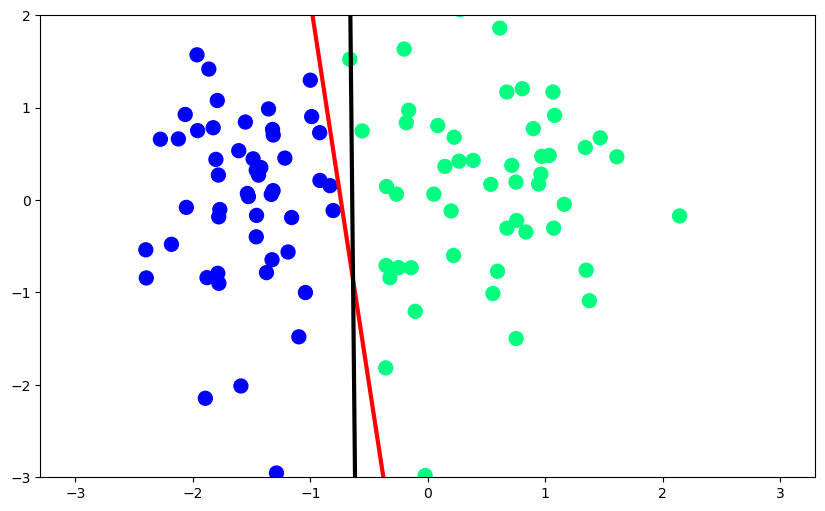

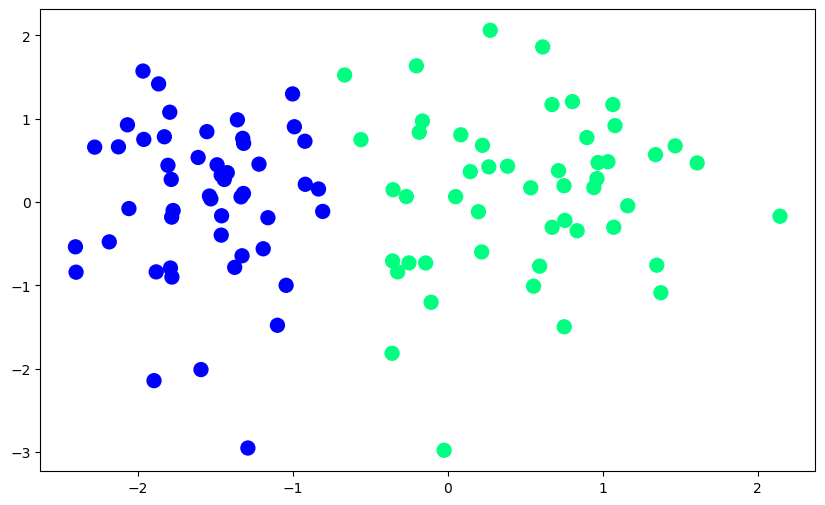

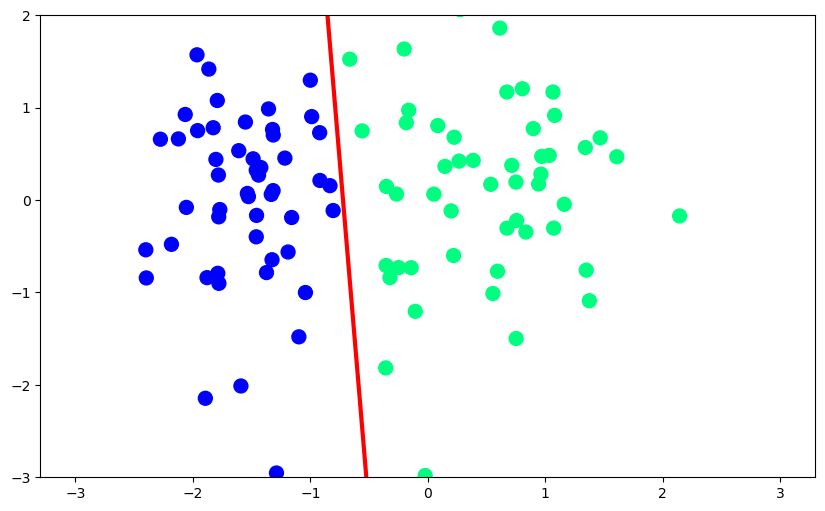

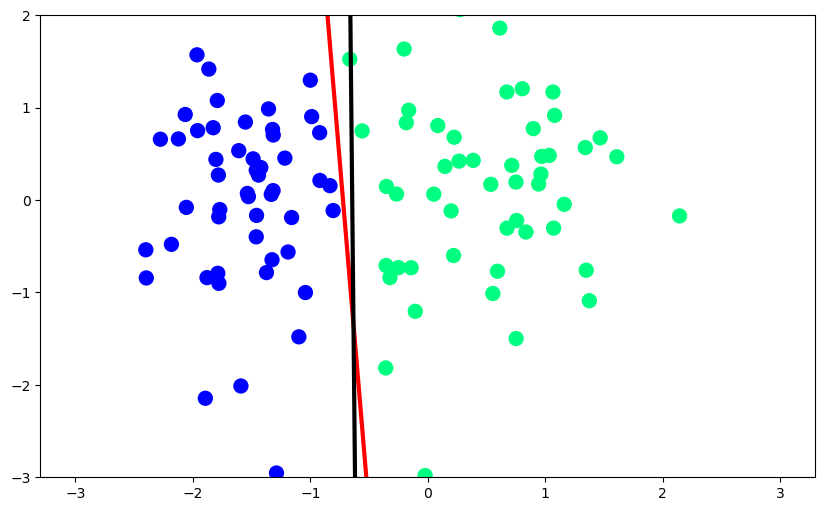

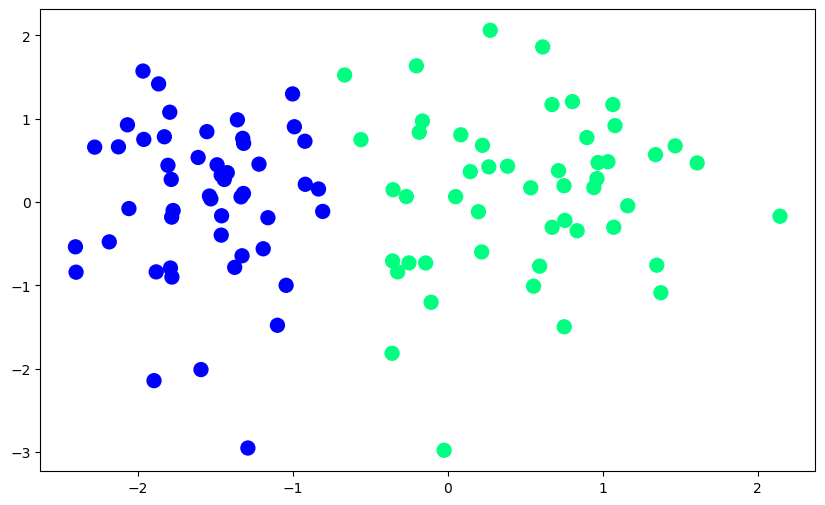

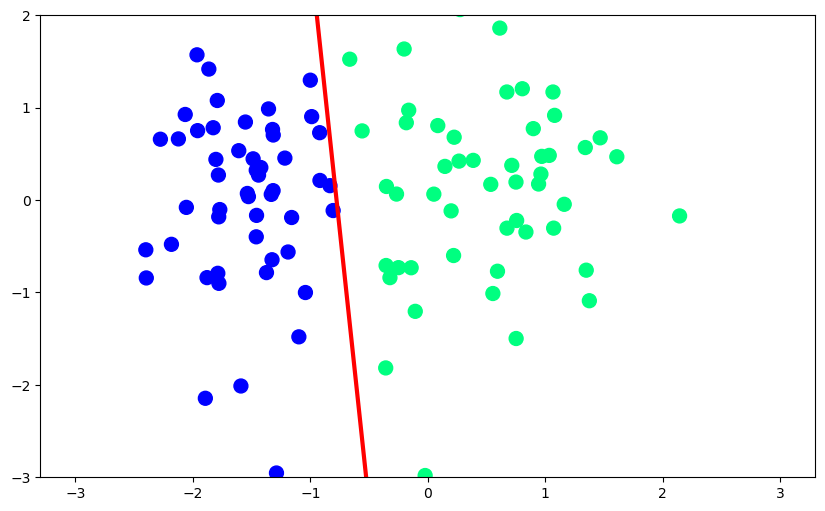

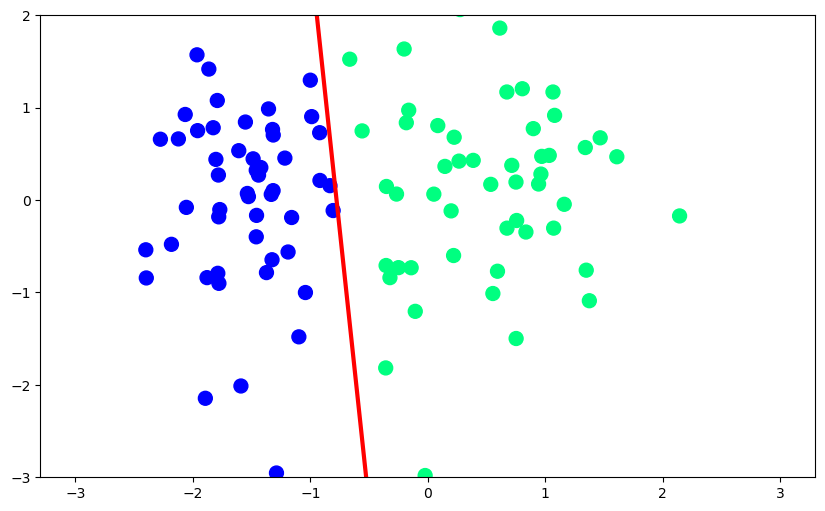

In [161]:
plt.figure(figsize=(10,6))
plt.plot(x_input, y_input, color='red', linewidth=3)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
plt.ylim(-3,2)
plt.show()

In [162]:
def perceptron(X,y):

    m = []
    b = []

    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(200):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

        m.append(-(weights[1]/weights[2]))
        b.append(-(weights[0]/weights[2]))
    return m,b

In [163]:
m,b = perceptron(X,y)

In [164]:
%matplotlib notebook
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation
from IPython.display import HTML

In [165]:
fig, ax = plt.subplots(figsize=(9,5)) # Create Figure & Axis
ax = fig.add_subplot(111) # Animation needs axis control: Update labels, lines, limits

x_i = np.arange(-3, 3, 0.1) # Creates evenly spaced numbers - np.arange(start, stop, step)
y_i = x_i*m[0] + b[0] # Compute initial Y values Where: m[0] → slope at epoch 1, b[0] → intercept at epoch 1
ax.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100) # Feature 1 → X-axis, Feature 2 → Y-axis, Color → class label
line, = ax.plot(x_i, x_i*m[0]+b[0], 'r-', linewidth=2) # plot() returns a list: [Line2D], where 'r-' Red Solid line
plt.ylim(-3,3) # vertical range

def update(i): # If frames = 200 → function runs 200 times
    label = 'epoch {0}'.format(i+1) # epoch 1, epoch 2, ..... epoch 200
    line.set_ydata(x_i*m[i] + b[i]) # animation step
    ax.set_xlabel(label) # Shows epoch number below plot
    # return line, ax

# frames=Total animation steps, interval=Time between frames (ms), repeat=True means After frame 200 → restart
anim = FuncAnimation(fig, update, repeat=True, frames=200, interval=100)
HTML(anim.to_jshtml())

<IPython.core.display.Javascript object>

# Logistic Regression using Scikit-Learn Implementation

In [166]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X,y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [167]:
m = -(lr.coef_[0][0] / lr.coef_[0][1])
b = -(lr.intercept_ / lr.coef_[0][1])

In [168]:
x_input1 = np.linspace(-3, 3, 100)
y_input1 = m*x_input1 + b

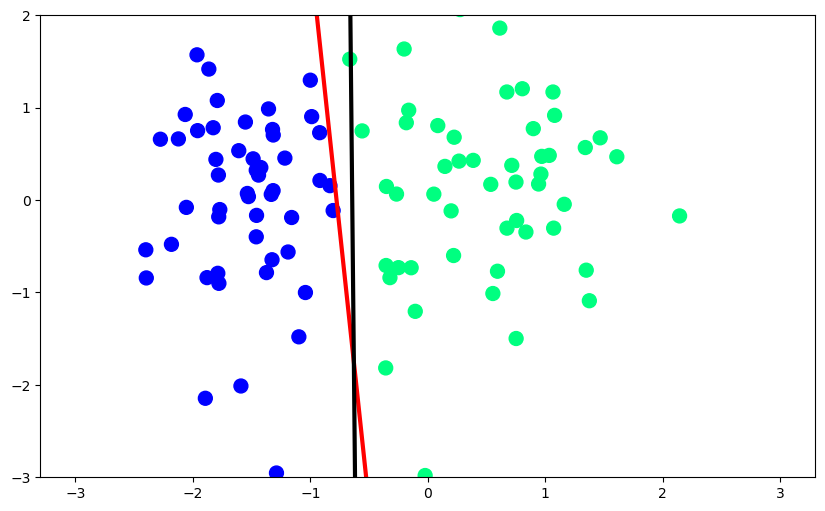

In [169]:
%matplotlib inline

plt.figure(figsize=(10,6))
plt.plot(x_input, y_input, color='red', linewidth=3)
plt.plot(x_input1, y_input1, color='black', linewidth=3)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
plt.ylim(-3,2)
plt.show()

- Logistic Regression model is better than perceptron model becouse it is symmetrically dividing the data

## Perceptron Trick by changing the Sigmoid Function in place of Step Function 

- We are adjusting the data points using both incorrectly classified points and correctly classified points
- Misclassified classified points pull the line toward them and Correctly Classified points push the line away from them
- From above two lines it will create an Equilibrium and create a line approx to Scikit-Learn Logistic Regression 

In [188]:
from sklearn.datasets import make_classification
import numpy as np
X,y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0, n_classes=2,
                          n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=15)

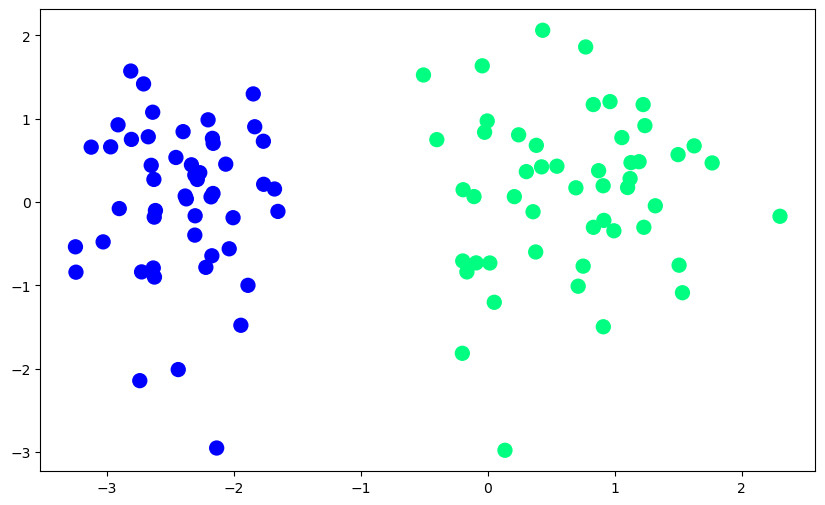

In [189]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(10,6))
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
plt.show()

In [204]:
def perceptron(X,y):
    
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = sigmoid(np.dot(X[j],weights))
        weights = weights + lr*(y[j] - y_hat)*X[j]

    return weights[0], weights[1:]


In [205]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [206]:
intercept_,coef_ = perceptron(X,y)

In [207]:
print(coef_)
print(intercept_)

[3.47151591 0.16050297]
2.9621645305712923


In [208]:
m = -(coef_[0] / coef_[1])
b = -(intercept_ / coef_[1])

In [209]:
x_input2 = np.linspace(-3,3,100)
y_input2 = m*x_input2 + b

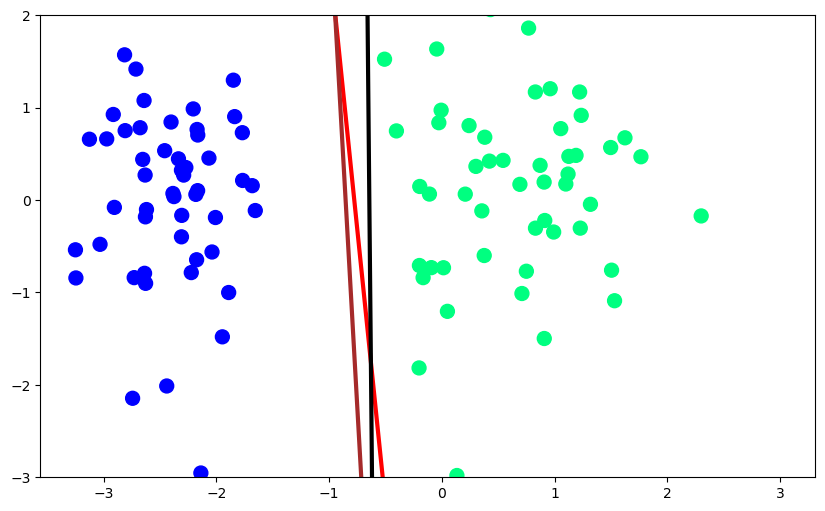

In [210]:
%matplotlib inline

plt.figure(figsize=(10,6))
plt.plot(x_input, y_input, color='red', linewidth=3)
plt.plot(x_input1, y_input1, color='black', linewidth=3)
plt.plot(x_input2, y_input2, color='brown', linewidth=3)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=100)
plt.ylim(-3,2)
plt.show()

- Black-Logistic Regression, Red-Step function, brown-Sigmoid function